In [5]:
!pip install pandas matplotlib seaborn

zsh:1: command not found: pip


Successfully loaded 222,858 total sensor events.


/var/folders/sj/99l98wg108bbw1zh4wr9w7100000gn/T/ipykernel_5488/2826937332.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_sensors.values, y=top_sensors.index, palette="viridis")


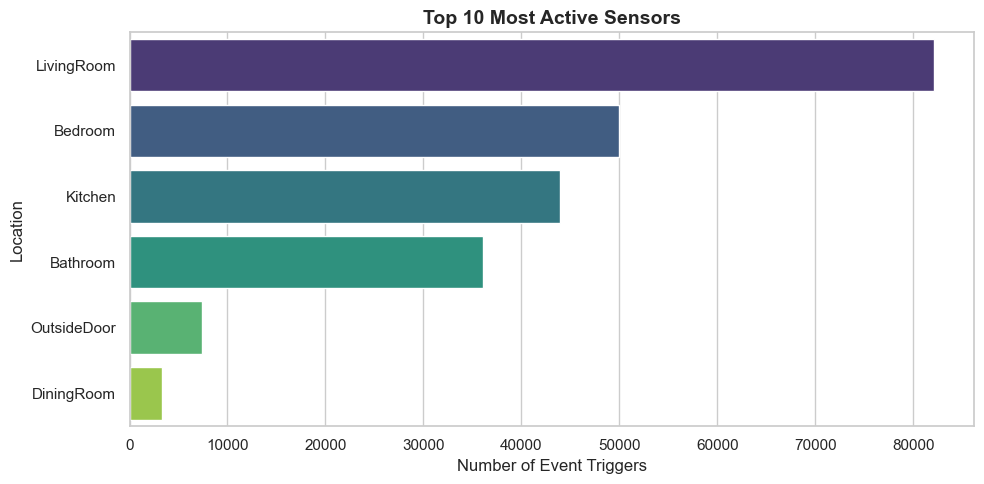

/var/folders/sj/99l98wg108bbw1zh4wr9w7100000gn/T/ipykernel_5488/2826937332.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Hour", data=df, palette="crest")


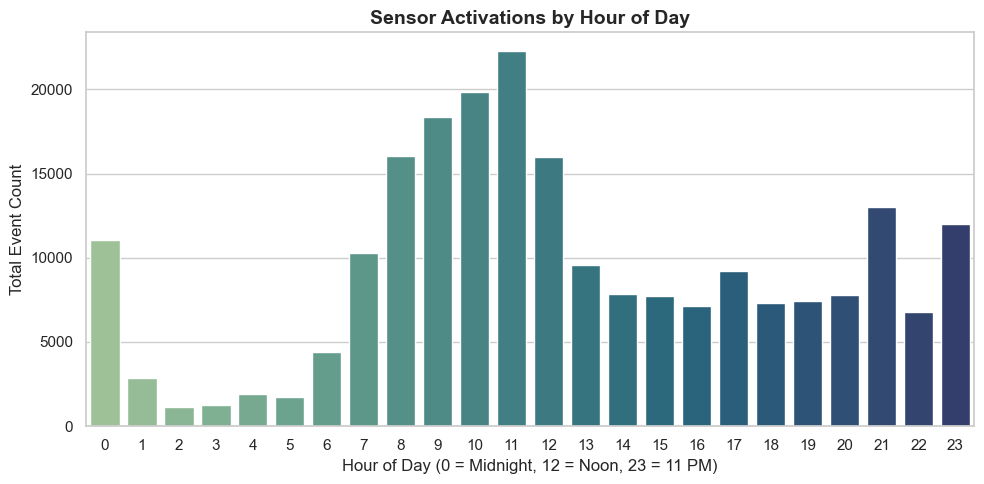

Total complete episodes (begin/end pairs): 2,645

Episodes and total hours per activity:
                  Episodes  Total_Hours
Activity                               
Toilet                 355        13.86
Watch_TV               316       374.78
Sleep_Out_Of_Bed       190       249.65
Dress                  174        12.17
Leave_Home             170         0.92
Enter_Home             170         0.80
Personal_Hygiene       156        14.80
Read                    87        47.30
Cook_Breakfast          79         9.81
Sleep                   75       383.43


/var/folders/sj/99l98wg108bbw1zh4wr9w7100000gn/T/ipykernel_5488/2826937332.py:98: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/sj/99l98wg108bbw1zh4wr9w7100000gn/T/ipykernel_5488/2826937332.py:108: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


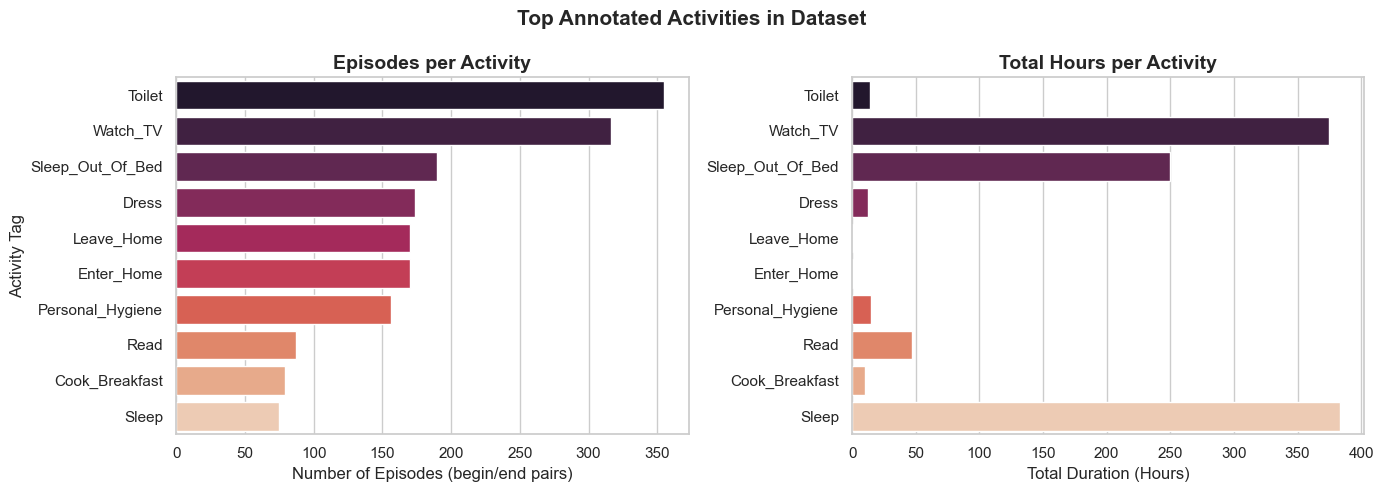

Total events occurring within < 1 second of prior event: 56,989 (25.57%)


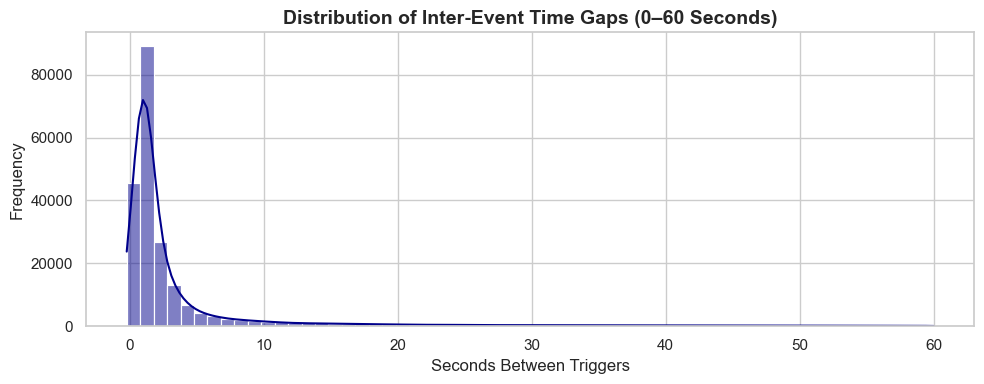


Duplicate Reports by Sensor Location:
Sensor_ID
Kitchen       5285
Bedroom       4351
LivingRoom    2797
Name: count, dtype: int64


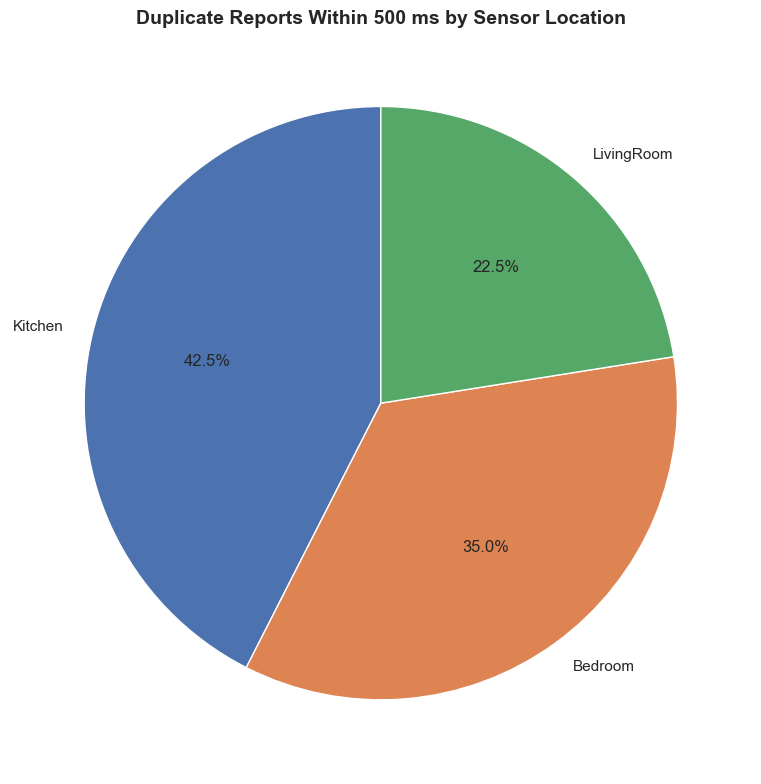


Sensor Status Distribution:
Status
ON       110816
OFF      110813
CLOSE       615
OPEN        614
Name: count, dtype: int64

Sensor Status Percentages:
ON: 49.72%
OFF: 49.72%
CLOSE: 0.28%
OPEN: 0.28%


/var/folders/sj/99l98wg108bbw1zh4wr9w7100000gn/T/ipykernel_5488/2826937332.py:218: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


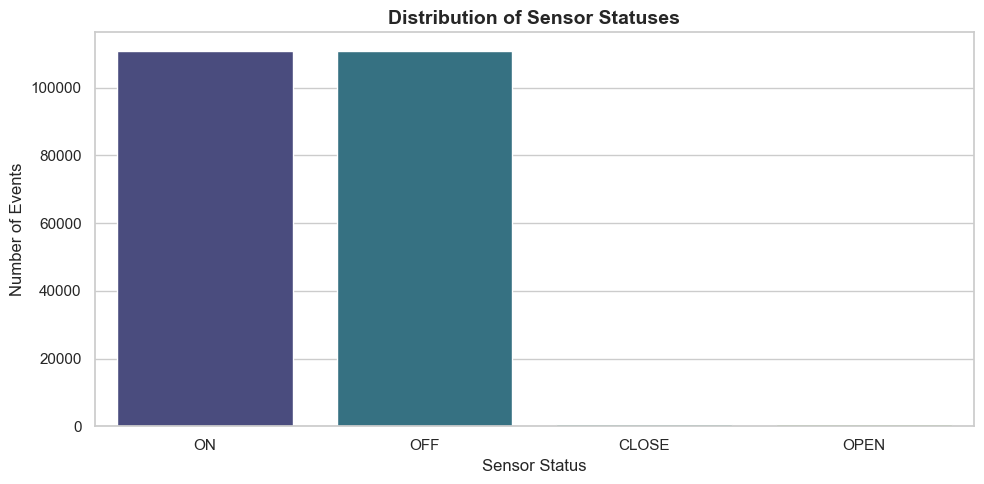

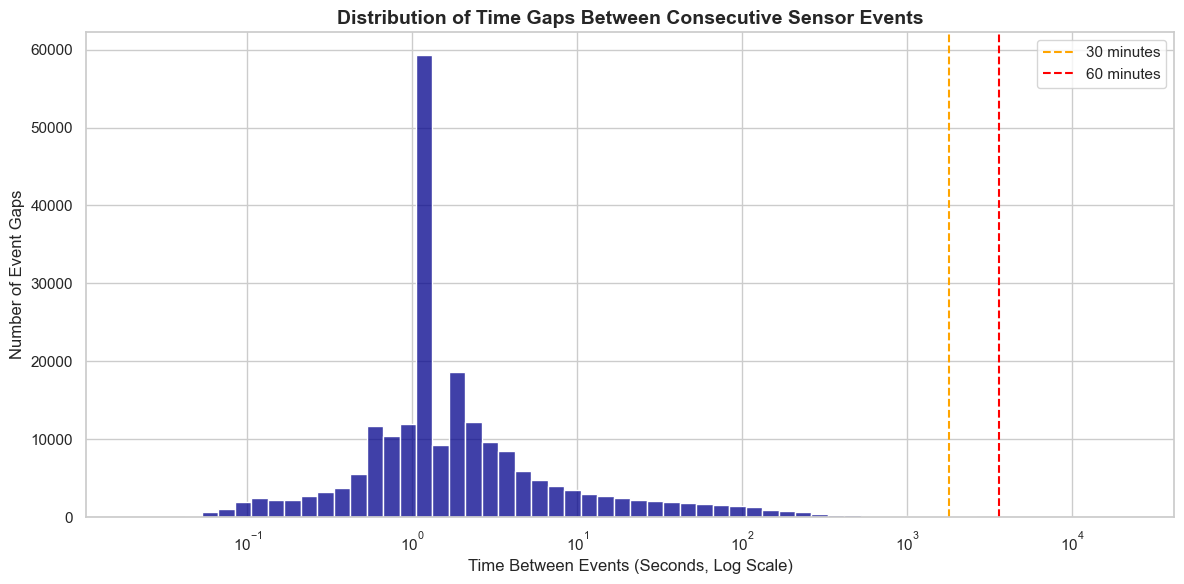

In [6]:
import pandas as pd

file_path = "hh101.csv"

# Load using comma separator
df = pd.read_csv(
    file_path,
    sep=",",
    names=["Date", "Time", "Sensor_ID", "Status", "Activity_Label"],
    engine="python",
)

# Combine Date and Time into a single Datetime index
df["Timestamp"] = pd.to_datetime(df["Date"] + " " + df["Time"])
df.set_index("Timestamp", inplace=True)

# Drop redundant string date/time columns to keep the dataset clean
df.drop(columns=["Date", "Time"], inplace=True)

print(f"Successfully loaded {len(df):,} total sensor events.")
df.head(10)

# Cell 1: Most Active Sensors (Bar Chart)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))
top_sensors = df["Sensor_ID"].value_counts().head(10)
sns.barplot(x=top_sensors.values, y=top_sensors.index, palette="viridis")

plt.title("Top 10 Most Active Sensors", fontsize=14, fontweight="bold")
plt.xlabel("Number of Event Triggers")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

# Cell 2: Diurnal Activity Patterns (Hour of Day)

plt.figure(figsize=(10, 5))
df["Hour"] = df.index.hour

sns.countplot(x="Hour", data=df, palette="crest")
plt.title("Sensor Activations by Hour of Day", fontsize=14, fontweight="bold")
plt.xlabel("Hour of Day (0 = Midnight, 12 = Noon, 23 = 11 PM)")
plt.ylabel("Total Event Count")
plt.tight_layout()
plt.show()

# Cell 3: Labeled Activity Distribution (episodes = begin/end pairs)

# Keep only labeled rows and split e.g. 'Step_Out="begin"' into name + marker
labels = df["Activity_Label"].dropna().astype(str)
labels = labels[labels.str.contains("=")]

activity_name = labels.str.split("=").str[0].str.strip()
marker = labels.str.split("=").str[1].str.strip().str.strip('"').str.lower()

# Pair each "begin" with the next "end" of the same activity -> one episode
open_starts = {}
episodes = []

for ts, act, mk in zip(labels.index, activity_name, marker):
    if mk == "begin":
        open_starts[act] = ts
    elif mk == "end" and act in open_starts:
        start = open_starts.pop(act)
        episodes.append(
            {
                "Activity": act,
                "Start": start,
                "End": ts,
                "Duration_Hours": (ts - start).total_seconds() / 3600,
            }
        )

episodes_df = pd.DataFrame(episodes)

episode_counts = episodes_df["Activity"].value_counts().head(10)
total_hours = (
    episodes_df.groupby("Activity")["Duration_Hours"]
    .sum()
    .reindex(episode_counts.index)
)

print(f"Total complete episodes (begin/end pairs): {len(episodes_df):,}")
print("\nEpisodes and total hours per activity:")
print(
    pd.DataFrame(
        {"Episodes": episode_counts, "Total_Hours": total_hours.round(2)}
    )
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=episode_counts.values,
    y=episode_counts.index,
    palette="rocket",
    ax=axes[0],
)
axes[0].set_title("Episodes per Activity", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Number of Episodes (begin/end pairs)")
axes[0].set_ylabel("Activity Tag")

sns.barplot(
    x=total_hours.values,
    y=total_hours.index,
    palette="rocket",
    ax=axes[1],
)
axes[1].set_title("Total Hours per Activity", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Total Duration (Hours)")
axes[1].set_ylabel("")

plt.suptitle(
    "Top Annotated Activities in Dataset", fontsize=15, fontweight="bold"
)
plt.tight_layout()
plt.show()

# Cell 4: Data Quality Audit (Rapid Trigger / Sensor Bouncing)

# Calculate time difference in seconds between consecutive events
df["Time_Diff_Sec"] = df.index.to_series().diff().dt.total_seconds()

# Count rapid firings (< 1.0 second apart)
rapid_events = df[df["Time_Diff_Sec"] < 1.0]
rapid_pct = (len(rapid_events) / len(df)) * 100

print(
    f"Total events occurring within < 1 second of prior event: {len(rapid_events):,} ({rapid_pct:.2f}%)"
)

# Plot distribution of time differences up to 60 seconds
plt.figure(figsize=(10, 4))
sns.histplot(
    df[df["Time_Diff_Sec"] < 60]["Time_Diff_Sec"],
    bins=60,
    kde=True,
    color="darkblue",
)
plt.title(
    "Distribution of Inter-Event Time Gaps (0–60 Seconds)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Seconds Between Triggers")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Cell 5: Duplicate Reports by Location

duplicate_check = df.reset_index()

duplicate_check = duplicate_check.sort_values(["Sensor_ID", "Timestamp"])

duplicate_check["Sensor_Time_Diff"] = (
    duplicate_check.groupby("Sensor_ID")["Timestamp"]
    .diff()
    .dt.total_seconds()
)

duplicate_check["Previous_Status"] = (
    duplicate_check.groupby("Sensor_ID")["Status"].shift(1)
)

duplicate_check["Is_Duplicate"] = (
    (duplicate_check["Status"] == duplicate_check["Previous_Status"])
    & (duplicate_check["Sensor_Time_Diff"] <= 0.5)
)

duplicate_counts = (
    duplicate_check[duplicate_check["Is_Duplicate"]]
    ["Sensor_ID"]
    .value_counts()
)

print("\nDuplicate Reports by Sensor Location:")
print(duplicate_counts)

plt.figure(figsize=(8, 8))

plt.pie(
    duplicate_counts.values,
    labels=duplicate_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Duplicate Reports Within 500 ms by Sensor Location",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Cell 6: Sensor Status Distribution

status_counts = df["Status"].value_counts()

print("\nSensor Status Distribution:")
print(status_counts)

status_percent = (status_counts / len(df)) * 100

print("\nSensor Status Percentages:")
for status, percentage in status_percent.items():
    print(f"{status}: {percentage:.2f}%")

plt.figure(figsize=(10, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    palette="viridis"
)

plt.title(
    "Distribution of Sensor Statuses",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Sensor Status")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

# Cell 7: Distribution of Time Gaps and Long Inactivity Periods

time_diffs = df["Time_Diff_Sec"].dropna()
time_diffs = time_diffs[time_diffs > 0]

plt.figure(figsize=(12, 6))

sns.histplot(
    time_diffs,
    bins=60,
    log_scale=(True, False),
    color="darkblue"
)

plt.axvline(
    x=30 * 60,
    color="orange",
    linestyle="--",
    label="30 minutes"
)

plt.axvline(
    x=60 * 60,
    color="red",
    linestyle="--",
    label="60 minutes"
)

plt.title(
    "Distribution of Time Gaps Between Consecutive Sensor Events",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Time Between Events (Seconds, Log Scale)")
plt.ylabel("Number of Event Gaps")
plt.legend()
plt.tight_layout()
plt.show()